## skip-gram 모델 실습

In [2]:
# 기본 skip-gram 클래스
# 입력단어와 주변단어를 룩업 테이블에서 가져와서 내적 계산
# 손실 함수를 통해 예측 오차를 최소화하는 방식으로 학습됨

from torch import nn

class VanillaSkipgram(nn.Module):
  def __init__(self, vocab_size, embedding_dim):
    super().__init__()

    self.embedding= nn.Embedding(
        num_embeddings=vocab_size,
        embedding_dim=embedding_dim,
    )

    self.linear=nn.Linear(
        in_features=embedding_dim,
        out_features=vocab_size,
    )

  def forward(self, input_ids):
    embeddings=self.embedding(input_ids)
    output=self.linear(embeddings)
    return output

In [3]:
!pip install Korpora konlpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 41.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [konlpy]


In [4]:
# 영화 리뷰 데이터세트 전처리
import pandas as pd
from Korpora import Korpora
from konlpy.tag import Okt

corpus=Korpora.load("nsmc")
corpus=pd.DataFrame(corpus.test) # test 세트

tokenizer=Okt() # 형태소 추출
tokens=[tokenizer.morphs(review) for review in corpus.text]
print(tokens[:3])


    Korpora 는 다른 분들이 연구 목적으로 공유해주신 말뭉치들을
    손쉽게 다운로드, 사용할 수 있는 기능만을 제공합니다.

    말뭉치들을 공유해 주신 분들에게 감사드리며, 각 말뭉치 별 설명과 라이센스를 공유 드립니다.
    해당 말뭉치에 대해 자세히 알고 싶으신 분은 아래의 description 을 참고,
    해당 말뭉치를 연구/상용의 목적으로 이용하실 때에는 아래의 라이센스를 참고해 주시기 바랍니다.

    # Description
    Author : e9t@github
    Repository : https://github.com/e9t/nsmc
    References : www.lucypark.kr/docs/2015-pyconkr/#39

    Naver sentiment movie corpus v1.0
    This is a movie review dataset in the Korean language.
    Reviews were scraped from Naver Movies.

    The dataset construction is based on the method noted in
    [Large movie review dataset][^1] from Maas et al., 2011.

    [^1]: http://ai.stanford.edu/~amaas/data/sentiment/

    # License
    CC0 1.0 Universal (CC0 1.0) Public Domain Dedication
    Details in https://creativecommons.org/publicdomain/zero/1.0/



[nsmc] download ratings_train.txt: 14.6MB [00:00, 24.3MB/s]                            
[nsmc] download ratings_test.txt: 4.90MB [00:00, 35.4MB/s]                            


[['굳', 'ㅋ'], ['GDNTOPCLASSINTHECLUB'], ['뭐', '야', '이', '평점', '들', '은', '....', '나쁘진', '않지만', '10', '점', '짜', '리', '는', '더', '더욱', '아니잖아']]


In [5]:
# 단어 사전 구축
from collections import Counter

def build_vocab(corpus, n_vocab, special_tokens):
  counter=Counter()
  for tokens in corpus:
    counter.update(tokens)

  vocab=special_tokens
  for token, count in counter.most_common(n_vocab):
    vocab.append(token)

  return vocab

vocab=build_vocab(corpus=tokens, n_vocab=5000, special_tokens=["<unk>"])
#n_vocab= 구축할 단어 사전의 크기
#<unk> = OOV에 대응, 단어 사전 내에 없는 모든 단어

token_to_id={token: idx for idx, token in enumerate(vocab)}
id_to_token={idx: token for idx, token in enumerate(vocab)}

print(vocab[:10])
print(len(vocab))

['<unk>', '.', '이', '영화', '의', '..', '가', '에', '...', '을']
5001


In [6]:
# skip-gram의 단어 쌍 추출
def get_word_pairs(tokens, window_size):
  pairs=[]
  for sentence in tokens:
    sentence_length=len(sentence)
    # idx= 현재 단어의 인덱스
    # center_word 중심단어
    for idx, center_word in enumerate(sentence):
      window_start=max(0, idx-window_size)
      window_end= min(sentence_length, idx+window_size+1)
      center_word= sentence[idx]
      context_words=sentence[window_start:idx]+sentence[idx+1:window_end]
      for context_word in context_words:
        pairs.append((center_word, context_word))

  return pairs

word_pairs=get_word_pairs(tokens, window_size=2)
print(word_pairs[:5])


[('굳', 'ㅋ'), ('ㅋ', '굳'), ('뭐', '야'), ('뭐', '이'), ('야', '뭐')]


In [9]:
# 단어 쌍 -> 인덱스 쌍
def get_index_pairs(word_pairs, token_to_id):
  pairs=[]
  unk_index=token_to_id["<unk>"]

  for word_pair in word_pairs:
    center_word, context_word= word_pair
    center_index=token_to_id.get(center_word, unk_index)
    context_index= token_to_id.get(context_word, unk_index)
    pairs.append([center_index, context_index])

  return pairs

index_pairs=get_index_pairs(word_pairs, token_to_id)
print(index_pairs[:5])



[[595, 100], [100, 595], [77, 176], [77, 2], [176, 77]]


In [10]:
# 데이터로더 적용
# 인덱스 쌍은 리스트 형식이었음
# 리스트 형식 -> 텐서 형식 변환
import torch
from torch.utils.data import TensorDataset, DataLoader

index_pairs=torch.tensor(index_pairs)
center_indexs= index_pairs[:,0]
context_indexs= index_pairs[:,1]

dataset=TensorDataset(center_indexs, context_indexs)
dataloader=DataLoader(dataset, batch_size=32, shuffle=True)

In [11]:
# skip-gram 모델 준비
from torch import optim

device="cuda" if torch.cuda.is_available() else "cpu"
word2vec=VanillaSkipgram(vocab_size=len(token_to_id), embedding_dim=128).to(device)
criterion= nn.CrossEntropyLoss().to(device)
optimizer=optim.SGD(word2vec.parameters(), lr=0.1)


In [13]:
# 모델 학습
for epoch in range(10):
  cost=0.0
  for input_ids, target_ids in dataloader:
    input_ids=input_ids.to(device)
    target_ids=target_ids.to(device)

    logits=word2vec(input_ids)
    loss= criterion(logits, target_ids)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    cost+=loss

  cost=cost/len(dataloader)
  print(f"Epoch: {epoch+1:4d}, Cost: {cost:.3f}")

Epoch:    1, Cost: 5.980
Epoch:    2, Cost: 5.931
Epoch:    3, Cost: 5.901
Epoch:    4, Cost: 5.878
Epoch:    5, Cost: 5.861
Epoch:    6, Cost: 5.846
Epoch:    7, Cost: 5.834
Epoch:    8, Cost: 5.822
Epoch:    9, Cost: 5.812
Epoch:   10, Cost: 5.802


In [14]:
# 임베딩 값 추출
token_to_embedding=dict()
embedding_matrix=word2vec.embedding.weight.detach().cpu().numpy()

for word, embedding in zip(vocab, embedding_matrix):
  token_to_embedding[word]= embedding

index=30
token=vocab[30]
token_embedding=token_to_embedding[token]
print(token)
print(token_embedding)

연기
[ 1.0962652   2.376473   -0.25189885 -0.6711573   0.38005126  1.0820094
  1.4885656  -0.9798802   0.21464004  1.5361016  -0.14131612 -0.65123725
 -1.1250426  -0.4455161   1.0513994  -0.25586045 -0.81574595  0.71282405
 -1.3902687   0.02819848 -0.2689745  -1.1252358   0.09891111 -0.04759374
  0.08508316 -0.5581659  -1.3501886   0.17676921 -0.60449    -0.43593422
  1.287018   -0.09089922  0.7791346   0.07518919 -0.2526986  -0.8888314
 -0.10869791 -0.95001215  0.9402846  -0.3819452   0.5501183   0.36344185
  0.81416917 -0.50697225  0.1076954   1.671997    0.2996453   1.1048802
 -0.14834888  1.4765748  -0.4625986   0.07348403  0.89262486 -0.64590484
  2.0063407   0.77875286  0.163463   -0.7081312   0.620062    0.41779226
  0.11245931 -0.8845104   1.5696368  -0.8328854   0.47646803  1.3493484
 -0.79603773  0.4069499   0.2817512   0.11634905  1.0251582   0.1189105
 -0.88458997 -0.45270133  1.1329045  -0.7575678   0.84297574 -0.02047607
 -0.9223195   2.0720956   1.510307   -1.1331539  -1.0

In [18]:
# 단어 임베딩 유사도 계산: 코사인 유사도
import numpy as np
from numpy.linalg import norm

def cosine_similarity(a,b):
  cosine=np.dot(b,a)/(norm(b, axis=1)* norm(a))
  return cosine

def top_n_index(cosine_matrix, n):
  closest_indexes= cosine_matrix.argsort()[::-1]
  top_n=closest_indexes[1:n+1]
  return top_n

cosine_matrix=cosine_similarity(token_embedding, embedding_matrix)
top_n= top_n_index(cosine_matrix, n=5)

print(f"{token}와 가장 유사한 5개 단어")
for index in top_n:
  print(f"{id_to_token[index]} - 유사도 : {cosine_matrix[index]:.4f}")

연기와 가장 유사한 5개 단어
관계 - 유사도 : 0.3373
배우 - 유사도 : 0.3299
탈 - 유사도 : 0.3033
집중 - 유사도 : 0.2985
보던 - 유사도 : 0.2918


## Gensim 으로 word2vec 모델 학습하기
위의 경우, 데이터 수가 적어도 학습시간이 오래 걸린다.

-> 계층적 소프트맥스, 네거티브 샘플링 등을 이용해 효율적으로 학습할 수 있다.

--> Gensim 라이브러리를 통해 word2vec 같은 자연어 처리 모델을 쉽게 구성할 수 있다.

In [19]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 55.7 MB/s  0:00:00


In [20]:
# word2vec 모델 학습

from gensim.models import Word2Vec

word2vec=Word2Vec(
    sentences=tokens,
    vector_size=128,
    window=5,
    min_count=1,
    sg=1,
    epochs=3,
    max_final_vocab=10000
)


In [85]:
# 임베딩 추출 및 유사도 계산
word="연기"
print(word2vec.wv[word])
print(word2vec.wv.most_similar(word, topn=5))
print(word2vec.wv.similarity(w1=word, w2="연기력"))


[-0.7222693  -1.5923095   1.3245912   0.6510559   0.52988225  0.97668576
  1.1043041  -0.5827295  -0.13693354  1.6520648   0.6426238  -1.0353565
 -0.7743958  -0.15917611  1.1564407  -1.274861   -0.32399774  0.867343
 -1.559401    0.44664156 -0.29831374  1.807664    0.86755216 -1.9768571
 -1.2454034   0.04447842  0.01229995  0.5081285   0.87209606  1.7777267
 -0.80214816  1.081747    0.34139183  0.7009281   0.12929149  1.1744045
  0.11325303 -1.5038619  -0.8595172   0.5331956  -1.3812759   0.5728735
  0.7896472  -0.49936816  0.70671105  0.10411891 -2.7074416  -0.4370615
  2.4213836   0.35044786  1.7571478   1.5850456   1.2684609   0.7064205
 -1.1995522   0.5041301   1.2292055   1.1166656  -0.10727086 -0.02310735
 -0.76090735  0.01152378 -0.83775336 -0.52321887  2.1276927  -0.0438708
 -0.6181989  -0.06107939  0.35230464 -1.148383    0.8025178  -0.6944785
 -2.497335   -0.32189733  0.5975495  -1.1677525  -0.34309566  0.7087845
 -1.0478406   1.300934   -0.17829226  0.78103846  0.5876803   2

## fastText

word2vec 처럼 CBoW, Skip-gram으로 구성되며 네거티브 샘플링 기법을 사용해 학습한다.

그러나, word2vec이 기본 단위로 모델을 학습했다면 fastText는 하위단어로 학습한다.

Word2Vec 모델볼다 입력 단어를 구성하는 데 조금 더 복잡한 과정이 필요하고 모든 하위 단어 크기를 갖는 임베딩 계층이 필요하다.

In [27]:
# KorNLI 데이터 세트 전처리
from Korpora import Korpora

corpus=Korpora.load("kornli")
corpus_texts=corpus.get_all_texts() + corpus.get_all_pairs()
tokens=[sentence.split() for sentence in corpus_texts]

print(tokens[:3])


    Korpora 는 다른 분들이 연구 목적으로 공유해주신 말뭉치들을
    손쉽게 다운로드, 사용할 수 있는 기능만을 제공합니다.

    말뭉치들을 공유해 주신 분들에게 감사드리며, 각 말뭉치 별 설명과 라이센스를 공유 드립니다.
    해당 말뭉치에 대해 자세히 알고 싶으신 분은 아래의 description 을 참고,
    해당 말뭉치를 연구/상용의 목적으로 이용하실 때에는 아래의 라이센스를 참고해 주시기 바랍니다.

    # Description
    Author : KakaoBrain
    Repository : https://github.com/kakaobrain/KorNLUDatasets
    References :
        - Ham, J., Choe, Y. J., Park, K., Choi, I., & Soh, H. (2020). KorNLI and KorSTS: New Benchmark
           Datasets for Korean Natural Language Understanding. arXiv preprint arXiv:2004.03289.
           (https://arxiv.org/abs/2004.03289)

    This is the dataset repository for our paper
    "KorNLI and KorSTS: New Benchmark Datasets for Korean Natural Language Understanding."
    (https://arxiv.org/abs/2004.03289)
    We introduce KorNLI and KorSTS, which are NLI and STS datasets in Korean.

    # License
    Creative Commons Attribution-ShareAlike license (CC BY-SA 4.0)
    Details in https://creativecommons.org/licenses

[kornli] download multinli.train.ko.tsv: 83.6MB [00:00, 154MB/s]                            
[kornli] download snli_1.0_train.ko.tsv: 78.5MB [00:00, 166MB/s]                            
[kornli] download xnli.dev.ko.tsv: 516kB [00:00, 3.83MB/s]                            
[kornli] download xnli.test.ko.tsv: 1.04MB [00:00, 14.7MB/s]


[['개념적으로', '크림', '스키밍은', '제품과', '지리라는', '두', '가지', '기본', '차원을', '가지고', '있다.'], ['시즌', '중에', '알고', '있는', '거', '알아?', '네', '레벨에서', '다음', '레벨로', '잃어버리는', '거야', '브레이브스가', '모팀을', '떠올리기로', '결정하면', '브레이브스가', '트리플', 'A에서', '한', '남자를', '떠올리기로', '결정하면', '더블', 'A가', '그를', '대신하러', '올라가고', 'A', '한', '명이', '그를', '대신하러', '올라간다.'], ['우리', '번호', '중', '하나가', '당신의', '지시를', '세밀하게', '수행할', '것이다.']]


**KorNLI 데이터 세트** = 한국어 자연어 추론을 위한 데이터세트

**자연어 추론**= 두 개 이상의 문장이 주어졌을 때 두 문장 간의 관계를 분류하는 작업
-> 함의 관계, 중립 관계, 불일치 관계

**코포라 라이브러리의 KorNLI 인스턴스**
*  get_all_texts get_all_pairs 메서드
* get_all_texts: 모든 문장을 튜플형태로 반환
* get_all_pairs: 입력 문장과 쌍을 이루는 대응 문장을 튜플 형태로 반환




In [28]:
# fastText 모델 실습

from gensim.models import FastText

fastText= FastText(
    sentences=tokens,
    vector_size=128,
    window=5,
    min_count=5,
    sg=1,
    epochs=3,
    min_n=2,
    max_n=6
)

In [29]:
# OOV 처리
# 사랑해요 -> 사랑+랑해+해요 등의 하위 단어로 분해
# 사랑해요 임베딩 = 분해된 하위 단어의 임베딩의 합
# 다른 단어에 등장했던 사랑, 해요 같은 하위단어를 통해 "사랑해요" 토큰의 임베딩 계산
oov_token="사랑해요"
oov_vector=fastText.wv[oov_token]

print(oov_token in fastText.wv.index_to_key)
print(fastText.wv.most_similar(oov_vector, topn=5))

False
[('사랑해', 0.9075824022293091), ('사랑', 0.8665387630462646), ('사랑한', 0.8652933835983276), ('사랑해서', 0.8397574424743652), ('사랑해.', 0.8352488875389099)]


## RNN

In [43]:
# 양방향 다층 신경망
import torch
from torch import nn

input_size=128
output_size=256
num_layers=3
bidirectional=True

model=nn.RNN(
    input_size=input_size,
    hidden_size=output_size,
    num_layers=num_layers,
    batch_first=True,
    bidirectional=bidirectional
)

batch_size=4
sequence_len=6

inputs=torch.rand(batch_size, sequence_len, input_size)
hidden=torch.rand(num_layers*(int(bidirectional)+1), batch_size, output_size)

outputs, hidden=model(inputs, hidden)
print(outputs.shape)
print(hidden.shape)

torch.Size([4, 6, 512])
torch.Size([6, 4, 256])


In [44]:
# 양방향 다층 장단기 메모리
import torch
from torch import nn

input_size=128
output_size=256
num_layers=3
bidirectional=True
proj_size=64

model=nn.LSTM(
    input_size=input_size,
    hidden_size=output_size,
    num_layers=num_layers,
    batch_first=True,
    bidirectional=bidirectional,
    proj_size= proj_size)

batch_size=4
sequence_len=6

inputs= torch.randn(batch_size, sequence_len, input_size)
h_0= torch.rand(
    num_layers* (int(bidirectional)+1),
    batch_size,
    proj_size if proj_size>0 else output_size,

)
c_0= torch.rand(num_layers*(int(bidirectional)+1), batch_size, output_size)
outputs, (h_n, c_n)=model(inputs, (h_0, c_0))
print(outputs.shape)
print(h_n.shape)
print(c_n.shape)

torch.Size([4, 6, 128])
torch.Size([6, 4, 64])
torch.Size([6, 4, 256])


## LSTM RNN -> 문장 긍/부정 분류 모델 학습하기




In [69]:
from torch import nn

class SentenceClassifier(nn.Module):
    def __init__(
        self,
        n_vocab,
        hidden_dim,
        embedding_dim,
        n_layers,
        dropout=0.5,
        bidirectional=True,
        model_type="lstm"
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=n_vocab,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        if model_type == "rnn":
            self.model = nn.RNN(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=n_layers,
                batch_first=True,
                dropout=dropout,
                bidirectional=bidirectional
            )

        elif model_type == "lstm":
            self.model = nn.LSTM(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=n_layers,
                batch_first=True,
                dropout=dropout,
                bidirectional=bidirectional
            )

        if bidirectional:
            self.classifier = nn.Linear(hidden_dim * 2, 1)
        else:
            self.classifier = nn.Linear(hidden_dim, 1)

        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs):
        embeddings = self.embedding(inputs)
        output, _ = self.model(embeddings)
        last_output = output[:, -1, :]
        last_output = self.dropout(last_output)
        logits = self.classifier(last_output)

        return logits

In [70]:
# 데이터세트 : 코포라 라이브러리의 네이버 영화 리뷰 감정 분석 데이터세트
import pandas as pd
from Korpora import Korpora

corpus=Korpora.load("nsmc")
corpus_df=pd.DataFrame(corpus.test) # test 세트

train=corpus_df.sample(frac=0.9, random_state=42)
test=corpus_df.drop(train.index)

print(train.head(5).to_markdown())
print("training data size: ", len(train))
print("testing data size: ", len(test))


    Korpora 는 다른 분들이 연구 목적으로 공유해주신 말뭉치들을
    손쉽게 다운로드, 사용할 수 있는 기능만을 제공합니다.

    말뭉치들을 공유해 주신 분들에게 감사드리며, 각 말뭉치 별 설명과 라이센스를 공유 드립니다.
    해당 말뭉치에 대해 자세히 알고 싶으신 분은 아래의 description 을 참고,
    해당 말뭉치를 연구/상용의 목적으로 이용하실 때에는 아래의 라이센스를 참고해 주시기 바랍니다.

    # Description
    Author : e9t@github
    Repository : https://github.com/e9t/nsmc
    References : www.lucypark.kr/docs/2015-pyconkr/#39

    Naver sentiment movie corpus v1.0
    This is a movie review dataset in the Korean language.
    Reviews were scraped from Naver Movies.

    The dataset construction is based on the method noted in
    [Large movie review dataset][^1] from Maas et al., 2011.

    [^1]: http://ai.stanford.edu/~amaas/data/sentiment/

    # License
    CC0 1.0 Universal (CC0 1.0) Public Domain Dedication
    Details in https://creativecommons.org/publicdomain/zero/1.0/

[Korpora] Corpus `nsmc` is already installed at /root/Korpora/nsmc/ratings_train.txt
[Korpora] Corpus `nsmc` is already installed at /root/Korpora/nsmc/ra

**데이터 전처리 과정**

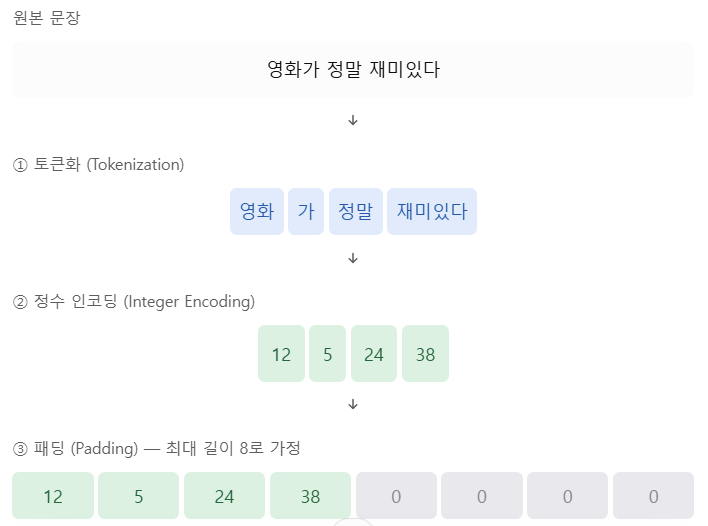

In [50]:
from konlpy.tag import Okt
from collections import Counter
from tqdm.auto import tqdm

# 토큰화 / 단어 사전 구축

def build_vocab(corpus, n_vocab, special_tokens):
    counter = Counter()

    for tokens in corpus:
        counter.update(tokens)

    vocab = special_tokens.copy()
    # 문장 길이를 맞추기 위해, <pad> 토큰을 special_token에 추가

    for token, count in counter.most_common(n_vocab):
        vocab.append(token)

    return vocab

tokenizer = Okt()
# Okt 토크나이저로 단어 토큰화, 단어 사전 구축

# 데이터 토큰화
train_tokens = [
    tokenizer.morphs(review)
    for review in tqdm(train.text, desc="Train 토큰화")
]

test_tokens = [
    tokenizer.morphs(review)
    for review in tqdm(test.text, desc="Test 토큰화")
]

# 단어 사전 구축
vocab = build_vocab(
    corpus=train_tokens,
    n_vocab=5000,
    special_tokens=["<pad>", "<unk>"]
)

token_to_id = {token: idx for idx, token in enumerate(vocab)}
id_to_token = {idx: token for idx, token in enumerate(vocab)}

print(vocab[:10])
print(len(vocab))

Train 토큰화:   0%|          | 0/45000 [00:00<?, ?it/s]

Test 토큰화:   0%|          | 0/5000 [00:00<?, ?it/s]

['<pad>', '<unk>', '.', '이', '영화', '의', '..', '가', '에', '...']
5002


In [71]:
# 정수 인코딩, 패딩
# 학습 데이터세트, 테스트 데이터세트를 단어 사전에 있는 정수로 인코딩한다.
import numpy as np

def pad_sequences(sequences, max_length, pad_value):
  result=list()
  for sequence in sequences:
    sequence= sequence[:max_length]
    pad_length= max_length- len(sequence)
    padded_sequence= sequence+[pad_value]*pad_length
    result.append(padded_sequence)
  return np.asarray(result)

unk_id=token_to_id["<unk>"]

train_ids=[[token_to_id.get(token, unk_id) for token in review] for review
           in train_tokens]
test_ids=[[token_to_id.get(token, unk_id) for token in review]
          for review in test_tokens]

max_length=32
pad_id=token_to_id["<pad>"]

train_ids=pad_sequences(train_ids, max_length, pad_id)
test_ids=pad_sequences(test_ids, max_length, pad_id)

print(train_ids[0])
print(test_ids[0])

[ 223 1716   10 4036 2095  193  755    4    2 2330 1031  220   26   13
 4839    1    1    1    2    0    0    0    0    0    0    0    0    0
    0    0    0    0]
[3307    5 1997  456    8    1 1013 3906    5    1    1   13  223   51
    3    1 4684    6    0    0    0    0    0    0    0    0    0    0
    0    0    0    0]


In [72]:
# 데이터 로더
import torch
from torch.utils.data import TensorDataset, DataLoader

train_ids= torch.tensor(train_ids)
test_ids=torch.tensor(test_ids)

train_labels=torch.tensor(train.label.values, dtype=torch.float32)
test_labels=torch.tensor(test.label.values, dtype=torch.float32)

train_dataset=TensorDataset(train_ids, train_labels)
test_dataset=TensorDataset(test_ids, test_labels)

train_loader=DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader=DataLoader(test_dataset, batch_size=16, shuffle=False)

In [73]:
# 손실 함수, 최적화 함수
from torch import optim

n_vocab=len(token_to_id)
hidden_dim=64 # 은닉 상태 크기
embedding_dim=128 # 임베딩 벡터 크기
n_layers=2

device="cuda" if torch.cuda.is_available() else "cpu"
classifier=SentenceClassifier(
    n_vocab=n_vocab, hidden_dim=hidden_dim, embedding_dim=embedding_dim,
    n_layers=n_layers
).to(device)

criterion=nn.BCEWithLogitsLoss().to(device) # 이진 교차 엔트로피 함수(긍부정 이진 분류니까)
optimizer= optim.RMSprop(classifier.parameters(), lr=0.001)
# RMSprop: 기울기 제곱값의 지수 가중 이동 평균(EWMA)을 사용
# 기울기 제곱값의 이동 평균이 작아지면 -> 학습률 증가
# 기울기 제곱값의 이동 평균이 커지면 -> 학습률 감소

In [74]:
# 모델 학습/ 테스트
import torch
from torch import nn, optim

def train(model, datasets, criterion, optimizer, device, interval):
  model.train()
  losses=list()

  for step, (input_ids, labels) in enumerate(datasets):
    input_ids=input_ids.to(device)
    labels=labels.to(device).unsqueeze(1)

    logits=model(input_ids)
    loss=criterion(logits, labels)
    losses.append(loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if step% interval==0:
      print(f"Train Loss {step}: {np.mean(losses)}")

def test(model, datasets, criterion, device):
  model.eval()
  losses=list()
  corrects=list()

  for step, (input_ids, labels) in enumerate(datasets):
    input_ids=input_ids.to(device)
    labels=labels.to(device).unsqueeze(1)

    logits=model(input_ids)
    loss=criterion(logits, labels)
    losses.append(loss.item())
    yhat=torch.sigmoid(logits)>.5

    corrects.extend(
        torch.eq(yhat, labels).cpu().tolist()
    )

  print(f"Val Loss: {np.mean(losses)}, Val Accurarcy: {np.mean(corrects)}")

epochs=5
interval=500
for epoch in range(epochs):
  train(classifier, train_loader, criterion, optimizer, device, interval)
  test(classifier, test_loader, criterion, device)



Train Loss 0: 0.6985109448432922
Train Loss 500: 0.6938835662044213
Train Loss 1000: 0.6855566746347791
Train Loss 1500: 0.6622441444176185
Train Loss 2000: 0.6413785064744687
Train Loss 2500: 0.6234934429248206
Val Loss: 0.5333510277370295, Val Accurarcy: 0.7438
Train Loss 0: 0.44495630264282227
Train Loss 500: 0.5296188484349412
Train Loss 1000: 0.5173609437463762
Train Loss 1500: 0.5067778550867713
Train Loss 2000: 0.5062048877777903
Train Loss 2500: 0.5002863704443264
Val Loss: 0.4602540367708419, Val Accurarcy: 0.7772
Train Loss 0: 0.35600802302360535
Train Loss 500: 0.4338709643025122
Train Loss 1000: 0.4301842024306079
Train Loss 1500: 0.4303136699641251
Train Loss 2000: 0.42759444243993716
Train Loss 2500: 0.4277976040468841
Val Loss: 0.4333256505929624, Val Accurarcy: 0.7984
Train Loss 0: 0.5243125557899475
Train Loss 500: 0.3793454970458073
Train Loss 1000: 0.37921588627489417
Train Loss 1500: 0.37548596760398306
Train Loss 2000: 0.3769215446026965
Train Loss 2500: 0.37633555

In [75]:
# 학습이 완료된 딥러닝 모델에서
# 각 단어의 임베딩 벡터(Embedding Vector)를 추출하는 작업
token_to_embedding=dict()
embedding_matrix= classifier.embedding.weight.detach().cpu().numpy()

for word, emb in zip(vocab, embedding_matrix):
  token_to_embedding[word]=emb

token=vocab[1000]
print(token, token_to_embedding[token])

보고싶다 [ 2.2450142   0.46733993  0.6034302   1.0513964  -1.5697111  -0.16450536
  1.435269    0.4838213  -1.3800715   0.08126504 -3.313023   -0.7725603
  0.85101324 -0.39500442 -1.3281473  -2.6025486   1.8617224  -0.09146888
 -1.5991056   0.05272675 -0.44574273 -0.7336186   1.7003161   0.1679383
  1.3240491  -0.7683811   0.08960507 -1.2923943   1.4019381  -1.2412935
 -0.31793895 -0.90220624 -1.1680068   0.56565934  2.4492702  -0.4812808
 -2.470031   -0.7056987  -2.498679   -1.2010276   1.0462215  -1.1220827
  0.30758765  0.08466069 -0.72562665 -1.5332075  -0.1535197   0.31462783
  0.0462707  -1.1189811  -1.4730691  -0.12434384 -0.01275138 -0.610537
  1.393443   -1.2501997  -1.4859482   0.7173575  -0.7845171   1.632132
 -0.7745948   1.2418559   0.6105194   1.1434962   0.7616212   0.15205006
  0.333202   -1.223082   -0.7564016   1.4253134   0.3647051   0.13981266
 -0.5277282   0.87346286 -1.3240277  -0.23787858  1.0229993   1.6622871
 -1.2578659  -0.77091694 -2.4498339  -2.2459424   1.2129

### 사전 학습된 임베딩값을 초깃값으로 적용하여 모델 학습시키기
--> 모델 성능 개선
--> 사전 학습된 임베딩을 사용하더라도 해당 언어와 문제에 맞는 임베딩을 사용하는 것이 중요!

In [ ]:
from gensim.models import Word2Vec

word2vec = Word2Vec(
    sentences=train_tokens,
    vector_size=128,
    window=5,
    min_count=1,
    workers=4
)

word2vec.save("word2vec.model")

In [81]:
# 임베딩 계층 초기화
import numpy as np
import torch
from torch import nn
from gensim.models import Word2Vec

word2vec = Word2Vec.load("word2vec.model")

init_embeddings = np.zeros((n_vocab, embedding_dim))

for index, token in id_to_token.items():
    if token not in ["<pad>", "<unk>"] and token in word2vec.wv:
      # <pad> <unk> 는 초기화에서 제외
        init_embeddings[index] = word2vec.wv[token]

embedding_layer = nn.Embedding.from_pretrained(
    torch.tensor(init_embeddings, dtype=torch.float32),
    freeze=False,
    padding_idx=0
)

In [82]:
# 사전 학습된 임베딩 계층 적용
import torch
from torch import nn

class SentenceClassifier(nn.Module):
    def __init__(
        self,
        n_vocab,
        hidden_dim,
        embedding_dim,
        n_layers,
        dropout=0.5,
        bidirectional=True,
        model_type="lstm",
        pretrained_embedding=None
    ):
        super().__init__()

        # 임베딩 계층 초기화
        if pretrained_embedding is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(pretrained_embedding, dtype=torch.float32)
            )
        else:
            self.embedding = nn.Embedding(
                num_embeddings=n_vocab,
                embedding_dim=embedding_dim,
                padding_idx=0
            )

        # RNN 모델
        if model_type == "rnn":
            self.model = nn.RNN(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=n_layers,
                batch_first=True,
                dropout=dropout,
                bidirectional=bidirectional
            )

        # LSTM 모델
        elif model_type == "lstm":
            self.model = nn.LSTM(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=n_layers,
                batch_first=True,
                dropout=dropout,
                bidirectional=bidirectional
            )

        # 분류 계층
        if bidirectional:
            self.classifier = nn.Linear(hidden_dim * 2, 1)
        else:
            self.classifier = nn.Linear(hidden_dim, 1)

        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs):
        embeddings = self.embedding(inputs)
        output, _ = self.model(embeddings)
        last_output = output[:, -1, :]
        last_output = self.dropout(last_output)
        logits = self.classifier(last_output)

        return logits

In [83]:
# 사전 학습된 임베딩을 사용한 모델 학습
classifier = SentenceClassifier(
    n_vocab=n_vocab, hidden_dim=hidden_dim, embedding_dim=embedding_dim,
    n_layers=n_layers, pretrained_embedding=init_embeddings
).to(device)

criterion = nn.BCEWithLogitsLoss().to(device)
optimizer = optim.RMSprop(classifier.parameters(), lr=0.001)

epochs = 5
interval = 500

for epoch in range(epochs):
    train(classifier, train_loader, criterion, optimizer, device, interval)
    test(classifier, test_loader, criterion, device)

Train Loss 0: 0.6933667659759521
Train Loss 500: 0.6925227719390702
Train Loss 1000: 0.6781224678982268
Train Loss 1500: 0.6458365184358562
Train Loss 2000: 0.6227848596986325
Train Loss 2500: 0.6025108929004063
Val Loss: 0.5137082363565129, Val Accurarcy: 0.7478
Train Loss 0: 0.7709881663322449
Train Loss 500: 0.4899155703966251
Train Loss 1000: 0.49058120442437125
Train Loss 1500: 0.4881211097323045
Train Loss 2000: 0.4846248262334263
Train Loss 2500: 0.4851447886845819
Val Loss: 0.4457302446753834, Val Accurarcy: 0.7894
Train Loss 0: 0.6768715381622314
Train Loss 500: 0.4583887207710338
Train Loss 1000: 0.45812881652351384
Train Loss 1500: 0.4610972207071859
Train Loss 2000: 0.4611723301955487
Train Loss 2500: 0.45886963016924404
Val Loss: 0.44135264566721627, Val Accurarcy: 0.7892
Train Loss 0: 0.37743663787841797
Train Loss 500: 0.44270464186064024
Train Loss 1000: 0.4479873122481795
Train Loss 1500: 0.4473455898131155
Train Loss 2000: 0.4486533230480583
Train Loss 2500: 0.4474125